In [ ]:
"""
Fetch Open-Meteo Historical (ERA5 / ERA5-Land) data for Punjab districts,
aggregate hourly -> daily, build model features, save to the Kaggle working dir.

Kaggle: turn Internet ON in notebook settings (Settings > Internet).
Output: /kaggle/working/openmeteo_punjab/punjab_features.csv
"""
import os
import time
import requests
import numpy as np
import pandas as pd

# ---------------- config ----------------
START, END = "2015-01-01", "2025-12-31"          # 11 full years
OUT_DIR = ("/kaggle/working/openmeteo_punjab"
           if os.path.exists("/kaggle/working") else "./openmeteo_punjab")
os.makedirs(OUT_DIR, exist_ok=True)

URL = "https://archive-api.open-meteo.com/v1/archive"

HOURLY = [
    "temperature_2m", "relative_humidity_2m", "vapour_pressure_deficit",
    "wind_speed_10m", "precipitation", "shortwave_radiation",
    "et0_fao_evapotranspiration",
    "soil_moisture_0_to_7cm", "soil_moisture_7_to_28cm",
    "soil_moisture_28_to_100cm", "soil_moisture_100_to_255cm",
]

# Approximate district HQ coordinates (ERA5 grid is ~9-25 km, so this is fine)
DISTRICTS = {
    "Amritsar": (31.634, 74.872), "Barnala": (30.378, 75.548),
    "Bathinda": (30.211, 74.945), "Faridkot": (30.673, 74.755),
    "Fatehgarh Sahib": (30.644, 76.395), "Fazilka": (30.403, 74.028),
    "Ferozepur": (30.925, 74.613), "Gurdaspur": (32.041, 75.405),
    "Hoshiarpur": (31.532, 75.917), "Jalandhar": (31.326, 75.576),
    "Kapurthala": (31.380, 75.381), "Ludhiana": (30.901, 75.857),
    "Malerkotla": (30.531, 75.880), "Mansa": (29.988, 75.393),
    "Moga": (30.816, 75.171), "Muktsar": (30.474, 74.516),
    "Pathankot": (32.274, 75.652), "Patiala": (30.339, 76.386),
    "Rupnagar": (30.966, 76.533), "SAS Nagar": (30.704, 76.717),
    "Sangrur": (30.245, 75.844), "SBS Nagar": (31.125, 76.116),
    "Tarn Taran": (31.451, 74.928),
}


# ---------------- fetching ----------------
def fetch_hourly(lat, lon, start, end, retries=12):
    params = {
        "latitude": lat, "longitude": lon,
        "start_date": start, "end_date": end,
        "hourly": ",".join(HOURLY),
        "timezone": "Asia/Kolkata",
    }
    for attempt in range(retries):
        try:
            r = requests.get(URL, params=params, timeout=180)
        except requests.RequestException:
            time.sleep(min(300, 30 * (attempt + 1)))
            continue

        if r.status_code == 429:
            wait = int(r.headers.get("Retry-After", 120))
            time.sleep(max(wait, 120))
            continue

        if r.status_code != 200:
            time.sleep(min(300, 30 * (attempt + 1)))
            continue

        try:
            j = r.json()
        except ValueError:
            # empty or non-JSON body = rate limit / server hiccup
            time.sleep(min(300, 60 * (attempt + 1)))
            continue

        if j.get("error"):
            reason = str(j.get("reason", ""))
            if "limit" in reason.lower():
                time.sleep(120)
                continue
            raise RuntimeError(f"Open-Meteo error: {reason}")

        df = pd.DataFrame(j["hourly"])
        df["time"] = pd.to_datetime(df["time"])
        return df
    raise RuntimeError(f"Too many retries for {lat},{lon} {start}")


def hourly_to_daily(h):
    d = h.set_index("time").resample("D").agg({
        "temperature_2m": ["mean", "max", "min"],
        "relative_humidity_2m": "mean",
        "vapour_pressure_deficit": "mean",
        "wind_speed_10m": ["mean", "max"],
        "precipitation": "sum",
        "shortwave_radiation": "sum",
        "et0_fao_evapotranspiration": "sum",
        "soil_moisture_0_to_7cm": "mean",
        "soil_moisture_7_to_28cm": "mean",
        "soil_moisture_28_to_100cm": "mean",
        "soil_moisture_100_to_255cm": "mean",
    })
    d.columns = [
        "temp_mean", "temp_max", "temp_min", "rh_mean", "vpd_mean",
        "wind_mean", "wind_max", "rain_mm", "solar_wh_m2", "et0_mm",
        "sm_0_7", "sm_7_28", "sm_28_100", "sm_100_255",
    ]
    d["solar_mj_m2"] = d.pop("solar_wh_m2") * 0.0036   # W/m2 hourly sum -> MJ/m2/day
    return d.reset_index().rename(columns={"time": "date"})


def fetch_all():
    frames = []
    years = range(int(START[:4]), int(END[:4]) + 1)
    total = len(DISTRICTS)
    for i, (name, (lat, lon)) in enumerate(DISTRICTS.items(), 1):
        path = os.path.join(OUT_DIR, f"daily_{name.replace(' ', '_')}.csv")
        if os.path.exists(path):                      # resumable
            frames.append(pd.read_csv(path, parse_dates=["date"]))
            print(f"[{i}/{total}] {name}: already saved, skipping fetch.")
            continue
        print(f"[{i}/{total}] {name}: fetching {START} -> {END} ...")
        parts = []
        for y in years:
            h = fetch_hourly(lat, lon, f"{y}-01-01", f"{y}-12-31")
            parts.append(hourly_to_daily(h))
            print(f"    {name} {y}: {len(h)} hourly rows fetched")
            time.sleep(10)
        d = pd.concat(parts, ignore_index=True)
        d.insert(0, "district", name)
        d.insert(1, "lat", lat)
        d.insert(2, "lon", lon)
        d.to_csv(path, index=False)
        print(f"[{i}/{total}] {name}: SAVED -> {path} (shape {d.shape})")
        frames.append(d)
    return pd.concat(frames, ignore_index=True)


# ---------------- features ----------------
def crop_and_das(date):
    """Paddy Jun-Oct, wheat Nov-Apr, May = fallow (edit to match PAU calendar)."""
    m, y = date.month, date.year
    if 6 <= m <= 10:
        return "paddy", (date - pd.Timestamp(y, 6, 1)).days
    if m >= 11:
        return "wheat", (date - pd.Timestamp(y, 11, 1)).days
    if m <= 4:
        return "wheat", (date - pd.Timestamp(y - 1, 11, 1)).days
    return "fallow", 0


def build_features(df):
    df = df.sort_values(["district", "date"]).reset_index(drop=True)
    g = df.groupby("district")

    for k in (1, 2, 3):
        df[f"sm_0_7_lag{k}"] = g["sm_0_7"].shift(k)
    df["rain_lag1"] = g["rain_mm"].shift(1)
    df["rain_3d_past"] = g["rain_mm"].transform(lambda s: s.rolling(3).sum())
    df["rain_7d_past"] = g["rain_mm"].transform(lambda s: s.rolling(7).sum())
    df["et0_3d_mean"] = g["et0_mm"].transform(lambda s: s.rolling(3).mean())
    # proxy for a rain forecast (in deployment use Open-Meteo's forecast API)
    df["rain_next3d"] = g["rain_mm"].transform(
        lambda s: s[::-1].rolling(3).sum()[::-1].shift(-1))

    df["doy_sin"] = np.sin(2 * np.pi * df["date"].dt.dayofyear / 365.25)
    df["doy_cos"] = np.cos(2 * np.pi * df["date"].dt.dayofyear / 365.25)

    cd = df["date"].apply(crop_and_das)
    df["crop"] = cd.str[0]
    df["days_after_sowing"] = cd.str[1]

    df["target_sm_next"] = g["sm_0_7"].shift(-1)       # TARGET: next-day moisture
    df["split"] = np.where(df["date"].dt.year <= 2022, "train", "test")

    return df.dropna(subset=["target_sm_next", "sm_0_7_lag3", "rain_7d_past"])


if __name__ == "__main__":
    raw = fetch_all()
    raw.to_csv(os.path.join(OUT_DIR, "punjab_daily_raw.csv"), index=False)

    feats = build_features(raw)
    feats.to_csv(os.path.join(OUT_DIR, "punjab_features.csv"), index=False)

    print("rows:", len(feats), "| districts:", feats["district"].nunique())
    print("null share per column (check for all-NaN variables):")
    print(raw.isna().mean().round(3).to_string())

    import shutil
    zip_path = "/kaggle/working/openmeteo_punjab_all"
    shutil.make_archive(zip_path, "zip", OUT_DIR)
    print("zipped:", zip_path + ".zip")

In [3]:
"""
Multi-horizon soil-moisture model (1, 3 and 5 days ahead), NO rain-forecast peek.
- more lag features (soil moisture, rain, ET0, temperature, deeper layer)
- target: CHANGE in soil moisture over H days, added back to today's value
- compares the model with "persistence" (future = today) at each horizon
- wheat irrigate/wait decision table at the 3-day horizon


"""
import os
import json
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, r2_score

PATH = "/kaggle/input/datasets/shauryapandey19/punjab-features/punjab_features.csv"
OUT = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
USE_FORECAST = False
TUNE = False
N_TRIALS = 40
HORIZONS = (1, 3, 5)
MAIN_H = 3

# params from your 1-day tuning run; used when TUNE=False
BEST = {"n_estimators": 200, "max_depth": 6, "learning_rate": 0.0147,
        "subsample": 0.92, "colsample_bytree": 0.69,
        "min_child_weight": 13, "reg_lambda": 0.124}

df = pd.read_csv(PATH, parse_dates=["date"]).sort_values(["district", "date"]).reset_index(drop=True)
g = df.groupby("district")

# ---------- features ----------
for w in (7, 14, 30):
    rain_w = g["rain_mm"].transform(lambda s, w=w: s.rolling(w).sum())
    et0_w = g["et0_mm"].transform(lambda s, w=w: s.rolling(w).sum())
    df[f"rain_{w}d"] = rain_w
    df[f"water_bal_{w}d"] = rain_w - et0_w

df["days_since_rain"] = g["rain_mm"].transform(lambda s: s.groupby((s > 1.0).cumsum()).cumcount())
df["heavy_rain"] = (df["rain_mm"] > 20).astype(int)
df["temp_range"] = df["temp_max"] - df["temp_min"]
df["das_paddy"] = df["days_after_sowing"] * (df["crop"] == "paddy")
df["das_wheat"] = df["days_after_sowing"] * (df["crop"] == "wheat")
df["crop_code"] = df["crop"].map({"paddy": 0, "wheat": 1, "fallow": 2})

# extra lags
for k in (4, 5, 6, 7):
    df[f"sm_0_7_lag{k}"] = g["sm_0_7"].shift(k)
for k in (2, 3, 4, 5, 6, 7):
    df[f"rain_lag{k}"] = g["rain_mm"].shift(k)
for k in (1, 2, 3):
    df[f"et0_lag{k}"] = g["et0_mm"].shift(k)
df["sm_7_28_lag1"] = g["sm_7_28"].shift(1)
df["sm_7_28_lag3"] = g["sm_7_28"].shift(3)
df["temp_mean_lag1"] = g["temp_mean"].shift(1)

# moisture trends and gaps
df["sm_trend1"] = df["sm_0_7"] - df["sm_0_7_lag1"]
df["sm_trend3"] = df["sm_0_7"] - df["sm_0_7_lag3"]
df["sm_trend7"] = df["sm_0_7"] - df["sm_0_7_lag7"]
df["sm_deep_trend3"] = df["sm_7_28"] - df["sm_7_28_lag3"]
df["sm_grad_top"] = df["sm_0_7"] - df["sm_7_28"]
df["sm_grad_deep"] = df["sm_7_28"] - df["sm_28_100"]
df["sm_mean7"] = g["sm_0_7"].transform(lambda s: s.rolling(7).mean())
df["sm_std7"] = g["sm_0_7"].transform(lambda s: s.rolling(7).std())

# antecedent precipitation index: recent rain counts more, fades over days
df["rain_api"] = g["rain_mm"].transform(lambda s: s.ewm(alpha=0.15, adjust=False).mean())

# ---------- targets for every horizon ----------
for H in HORIZONS:
    df[f"target_sm_h{H}"] = g["sm_0_7"].shift(-H)
    df[f"target_delta_h{H}"] = df[f"target_sm_h{H}"] - df["sm_0_7"]

drop = ["date", "district", "split", "crop", "target_sm_next"]
if not USE_FORECAST:
    drop.append("rain_next3d")
FEATURES = [c for c in df.columns if c not in drop and not c.startswith("target_")]
print("features used:", len(FEATURES), "| forecast included:", USE_FORECAST)

train_pool = df[df["date"].dt.year <= 2022]
test = df[df["date"].dt.year >= 2023]


def rows_for(frame, H):
    return frame.dropna(subset=[f"target_delta_h{H}"])


# ---------- optional tuning on the main horizon ----------
params = dict(BEST)
if TUNE:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    tp = rows_for(train_pool, MAIN_H)

    def objective(trial):
        p = {
            "n_estimators": trial.suggest_int("n_estimators", 200, 1200, step=100),
            "max_depth": trial.suggest_int("max_depth", 3, 9),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
            "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 20, log=True),
        }
        maes = []
        for vy in (2019, 2020, 2021, 2022):
            tr, va = tp[tp["date"].dt.year < vy], tp[tp["date"].dt.year == vy]
            m = XGBRegressor(**p, tree_method="hist", n_jobs=-1, random_state=0)
            m.fit(tr[FEATURES], tr[f"target_delta_h{MAIN_H}"])
            maes.append(mean_absolute_error(va[f"target_delta_h{MAIN_H}"], m.predict(va[FEATURES])))
        return float(np.mean(maes))

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=0))
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    params = study.best_params
    print("best params:", params)

# ---------- fit + test each horizon ----------
results, models, preds = [], {}, {}
for H in HORIZONS:
    tr, te = rows_for(train_pool, H), rows_for(test, H)
    m = XGBRegressor(**params, tree_method="hist", n_jobs=-1, random_state=0)
    m.fit(tr[FEATURES], tr[f"target_delta_h{H}"])
    d_pred = m.predict(te[FEATURES])
    level = te["sm_0_7"].values + d_pred
    y = te[f"target_sm_h{H}"].values
    mae_m = mean_absolute_error(y, level)
    mae_p = mean_absolute_error(y, te["sm_0_7"].values)
    results.append({
        "horizon_days": H, "test_rows": len(te),
        "MAE_model": round(mae_m, 5), "MAE_persistence": round(mae_p, 5),
        "improvement_%": round(100 * (1 - mae_m / mae_p), 1),
        "R2_delta": round(r2_score(te[f"target_delta_h{H}"], d_pred), 3),
    })
    models[H] = m
    preds[H] = te.assign(pred_h=level)

res = pd.DataFrame(results)
print("\n", res.to_string(index=False))
res.to_csv(os.path.join(OUT, "horizon_results.csv"), index=False)

imp = pd.Series(models[MAIN_H].feature_importances_, index=FEATURES).sort_values(ascending=False)
print(f"\ntop 15 features ({MAIN_H}-day model):\n", imp.head(15).round(4).to_string())
models[MAIN_H].save_model(os.path.join(OUT, f"xgb_h{MAIN_H}.json"))
json.dump(params, open(os.path.join(OUT, "best_params_h.json"), "w"), indent=2, default=float)

# ---------- wheat irrigate/wait table at the main horizon ----------
H = MAIN_H
t = preds[H]
t = t[(t["crop"] == "wheat") & (t["days_after_sowing"] <= 150)].copy()
wheat_train = train_pool[(train_pool["crop"] == "wheat") & (train_pool["days_after_sowing"] <= 150)]

rows = []
for pct in (15, 25, 35):
    thr = wheat_train.groupby("district")["sm_0_7"].quantile(pct / 100)
    t["thr"] = t["district"].map(thr)
    needed = t[f"target_sm_h{H}"] < t["thr"]
    advice = {"model": t["pred_h"] < t["thr"], "naive_today": t["sm_0_7"] < t["thr"]}
    das = t["days_after_sowing"]
    for N in (15, 20, 25):
        sched = (das >= 21) & ((das - 21) % N == 0)
        waste, real_need = sched & ~needed, sched & needed
        for name, adv in advice.items():
            skipped = sched & ~adv
            rows.append({
                "dry_pct": pct, "interval_days": N, "rule": name,
                "scheduled": int(sched.sum()),
                "skipped_%": 100 * skipped.sum() / sched.sum(),
                "wasteful_avoided_%": 100 * (skipped & ~needed).sum() / max(waste.sum(), 1),
                "needed_missed_%": 100 * (skipped & needed).sum() / max(real_need.sum(), 1),
            })

tab = pd.DataFrame(rows)
print(f"\nWheat decision table, {H}-day horizon:\n", tab.round(1).to_string(index=False))
print("\naverage over all rows, by rule:\n",
      tab.groupby("rule")[["skipped_%", "wasteful_avoided_%", "needed_missed_%"]].mean().round(1).to_string())
tab.round(1).to_csv(os.path.join(OUT, f"wheat_decision_h{H}.csv"), index=False)

features used: 63 | forecast included: False

  horizon_days  test_rows  MAE_model  MAE_persistence  improvement_%  R2_delta
            1      25162    0.01292          0.01525           15.3     0.228
            3      25116    0.02972          0.03258            8.8     0.184
            5      25070    0.03888          0.04250            8.5     0.197

top 15 features (3-day model):
 rain_lag1          0.0930
sm_0_7             0.0579
sm_trend1          0.0475
temp_min           0.0345
sm_trend7          0.0340
sm_0_7_lag1        0.0340
rain_mm            0.0330
sm_trend3          0.0321
sm_deep_trend3     0.0300
temp_range         0.0276
doy_cos            0.0228
sm_std7            0.0211
days_since_rain    0.0206
das_wheat          0.0186
sm_0_7_lag2        0.0174

Wheat decision table, 3-day horizon:
  dry_pct  interval_days        rule  scheduled  skipped_%  wasteful_avoided_%  needed_missed_%
      15             15       model        621       83.1                96.7       

In [4]:
# ================= FIX 1: safety margin, fair comparison =================
# Both rules get a margin. Margin is picked on 2023 only, final numbers on 2024-25.
# Rule: "skip only if score >= thr + margin". Bigger margin = fewer skips, fewer missed.
TARGET_MISSED = 15.0     # max % of needed irrigations we allow to be skipped (edit this)
MARGINS = np.round(np.arange(0, 0.0601, 0.005), 4)
PCTS, INTERVALS = (15, 25, 35), (15, 20, 25)

H = MAIN_H
w = preds[H]
w = w[(w["crop"] == "wheat") & (w["days_after_sowing"] <= 150)].copy()
val = w[w["date"].dt.year == 2023]
tst = w[w["date"].dt.year >= 2024]
thr_by_pct = {p: wheat_train.groupby("district")["sm_0_7"].quantile(p / 100) for p in PCTS}


def evaluate(d, score_col, margin):
    """Pooled over all (dry_pct, interval) scenarios."""
    skip_n = sched_n = miss_n = need_n = 0
    for p in PCTS:
        thr = d["district"].map(thr_by_pct[p])
        needed = d[f"target_sm_h{H}"] < thr
        skip_adv = d[score_col] >= thr + margin          # advisor says "skip"
        das = d["days_after_sowing"]
        for N in INTERVALS:
            sched = (das >= 21) & ((das - 21) % N == 0)
            skip = sched & skip_adv
            skip_n += skip.sum(); sched_n += sched.sum()
            miss_n += (skip & needed).sum(); need_n += (sched & needed).sum()
    return 100 * skip_n / sched_n, 100 * miss_n / max(need_n, 1)


rules = {"model": "pred_h", "naive_today": "sm_0_7"}

# 1) pick each rule's margin on 2023: most skips while missed <= TARGET_MISSED
chosen = {}
for name, col in rules.items():
    curve = [(m, *evaluate(val, col, m)) for m in MARGINS]
    ok = [c for c in curve if c[2] <= TARGET_MISSED]
    chosen[name] = max(ok, key=lambda c: c[1])[0] if ok else min(curve, key=lambda c: c[2])[0]
    print(f"VAL {name}: chosen margin = {chosen[name]}")

# 2) final report on 2024-25 at those margins
final = []
for name, col in rules.items():
    s, m = evaluate(tst, col, chosen[name])
    final.append({"rule": name, "margin": chosen[name], "skipped_%": round(s, 1), "needed_missed_%": round(m, 1)})
final = pd.DataFrame(final)
print(f"\nTEST 2024-25 (margin picked on 2023, target missed <= {TARGET_MISSED}%):\n", final.to_string(index=False))
final.to_csv(os.path.join(OUT, "fix1_final.csv"), index=False)

# 3) full test curves for both rules (plot skipped_% vs needed_missed_%)
curves = pd.DataFrame([{"rule": n, "margin": m, **dict(zip(("skipped_%", "needed_missed_%"), np.round(evaluate(tst, c, m), 1)))}
                       for n, c in rules.items() for m in MARGINS])
print("\nTEST curves:\n", curves.to_string(index=False))
curves.to_csv(os.path.join(OUT, "fix1_curves.csv"), index=False)

VAL model: chosen margin = 0.015
VAL naive_today: chosen margin = 0.01

TEST 2024-25 (margin picked on 2023, target missed <= 15.0%):
        rule  margin  skipped_%  needed_missed_%
      model   0.015       65.0             15.6
naive_today   0.010       63.8             17.2

TEST curves:
        rule  margin  skipped_%  needed_missed_%
      model   0.000       70.5             24.7
      model   0.005       68.5             21.5
      model   0.010       66.8             18.5
      model   0.015       65.0             15.6
      model   0.020       63.0             13.3
      model   0.025       61.2             11.5
      model   0.030       59.0              9.4
      model   0.035       56.9              7.9
      model   0.040       54.6              7.3
      model   0.045       51.6              5.7
      model   0.050       49.8              4.6
      model   0.055       47.7              3.5
      model   0.060       45.1              2.9
naive_today   0.000       67.1    

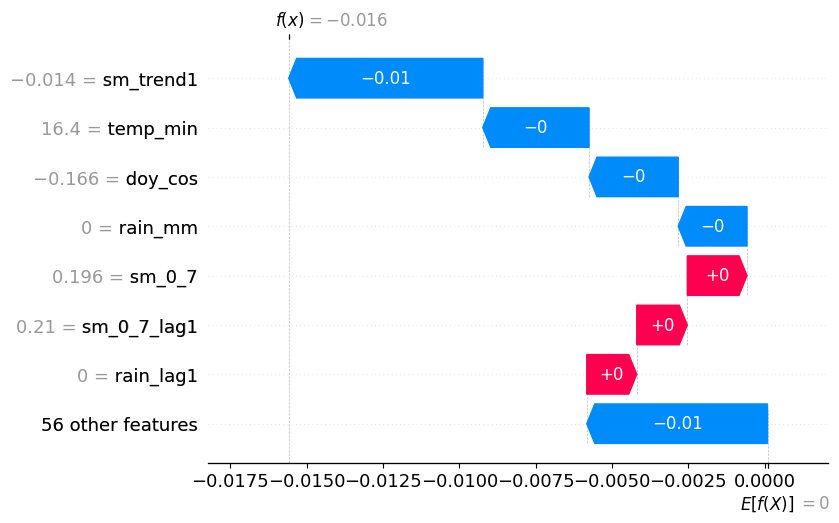

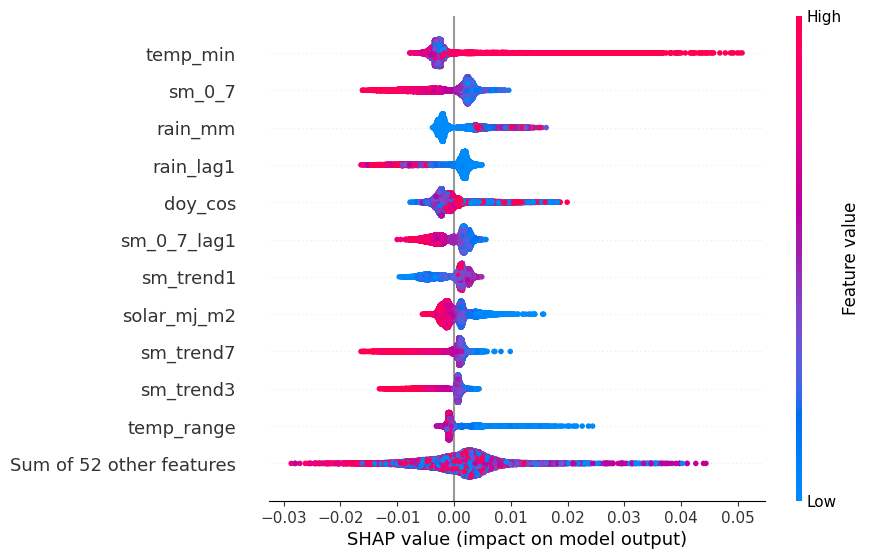

In [7]:
import shap
import matplotlib.pyplot as plt

te3 = preds[3]                                  # 3-day test rows
expl = shap.TreeExplainer(models[3])
sv = expl(te3[FEATURES])

i = te3.reset_index(drop=True).query("crop == 'wheat'").index[100]                                         # any row number, e.g. 0
shap.plots.waterfall(sv[i], max_display=8)

shap.plots.beeswarm(sv, max_display=12)

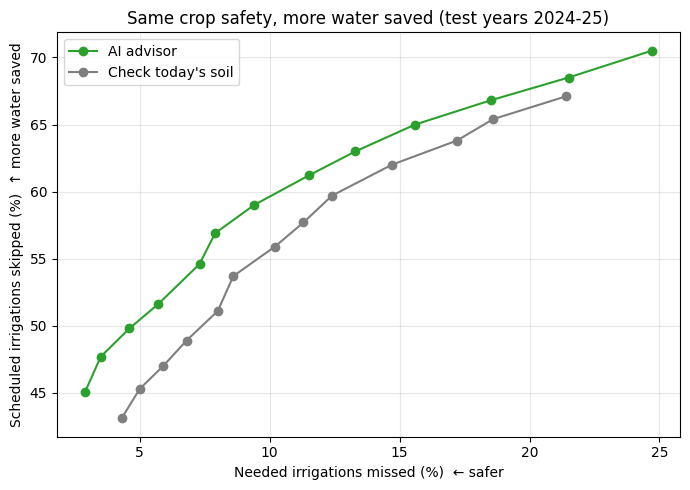

In [8]:


# Compare AI advisor and "check today's soil" at every safety setting
fig, ax = plt.subplots(figsize=(7, 5))
for name, label, color in [("model", "AI advisor", "tab:green"), ("naive_today", "Check today's soil", "tab:gray")]:
    d = curves[curves["rule"] == name]
    ax.plot(d["needed_missed_%"], d["skipped_%"], marker="o", color=color, label=label)

# Higher line = more water saved at the same crop safety
ax.set_xlabel("Needed irrigations missed (%)  ← safer")
ax.set_ylabel("Scheduled irrigations skipped (%)  ↑ more water saved")
ax.set_title("Same crop safety, more water saved (test years 2024-25)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/plot1_safety_vs_savings.png", dpi=200)
plt.show()

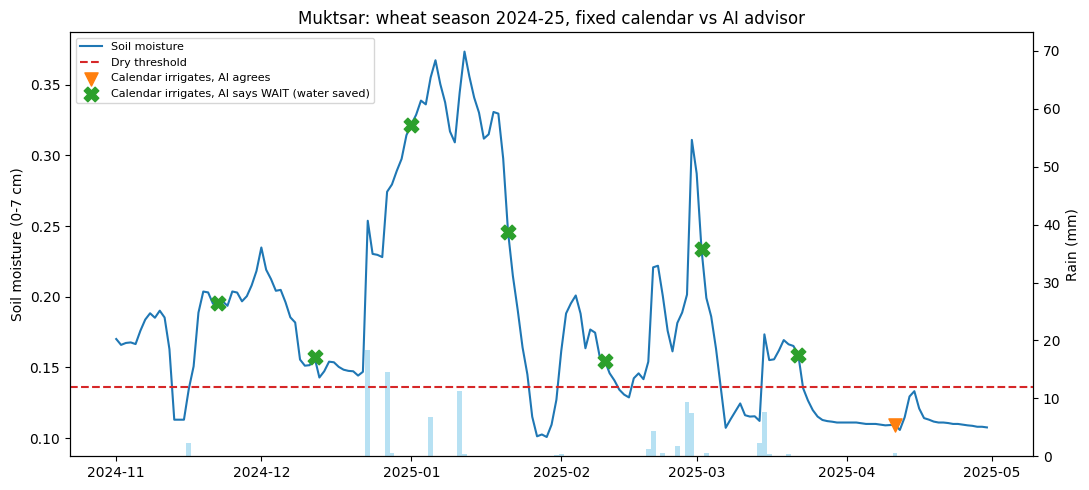

In [9]:
MARGIN = chosen["model"]

# Wheat rows for the 2024-25 season with the 25% dry threshold per district
w = preds[3]
w = w[(w["crop"] == "wheat") & (w["date"] >= "2024-10-15") & (w["date"] <= "2025-05-15")].copy()
w["thr"] = w["district"].map(wheat_train.groupby("district")["sm_0_7"].quantile(0.25))

# Mark days the fixed calendar irrigates (every 20 days) and days the AI says WAIT
das = w["days_after_sowing"]
w["calendar"] = (das >= 21) & ((das - 21) % 20 == 0)
w["wait"] = w["pred_h"] >= w["thr"] + MARGIN

# Pick the district where the AI saves the most calendar irrigations
DISTRICT = (w["calendar"] & w["wait"]).groupby(w["district"]).sum().idxmax()
s = w[w["district"] == DISTRICT].sort_values("date")
cal = s[s["calendar"]]

fig, ax = plt.subplots(figsize=(11, 5))
ax2 = ax.twinx()

# Rain bars sit behind the moisture line on the right axis
ax2.bar(s["date"], s["rain_mm"], color="skyblue", alpha=0.6, width=1, label="Rain")
ax2.set_ylim(0, s["rain_mm"].max() * 4)
ax2.set_ylabel("Rain (mm)")
ax.set_zorder(ax2.get_zorder() + 1)
ax.patch.set_visible(False)

# Soil moisture line and the dry threshold
ax.plot(s["date"], s["sm_0_7"], color="tab:blue", label="Soil moisture")
ax.axhline(s["thr"].iloc[0], color="tab:red", ls="--", label="Dry threshold")

# Green X = calendar would irrigate but AI says WAIT; orange triangle = AI agrees
agree, saved = cal[~cal["wait"]], cal[cal["wait"]]
ax.scatter(agree["date"], agree["sm_0_7"], marker="v", color="tab:orange", s=90, zorder=5, label="Calendar irrigates, AI agrees")
ax.scatter(saved["date"], saved["sm_0_7"], marker="X", color="tab:green", s=110, zorder=5, label="Calendar irrigates, AI says WAIT (water saved)")

ax.set_ylabel("Soil moisture (0-7 cm)")
ax.set_title(f"{DISTRICT}: wheat season 2024-25, fixed calendar vs AI advisor")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT}/plot2_season_timeline.png", dpi=200)
plt.show()

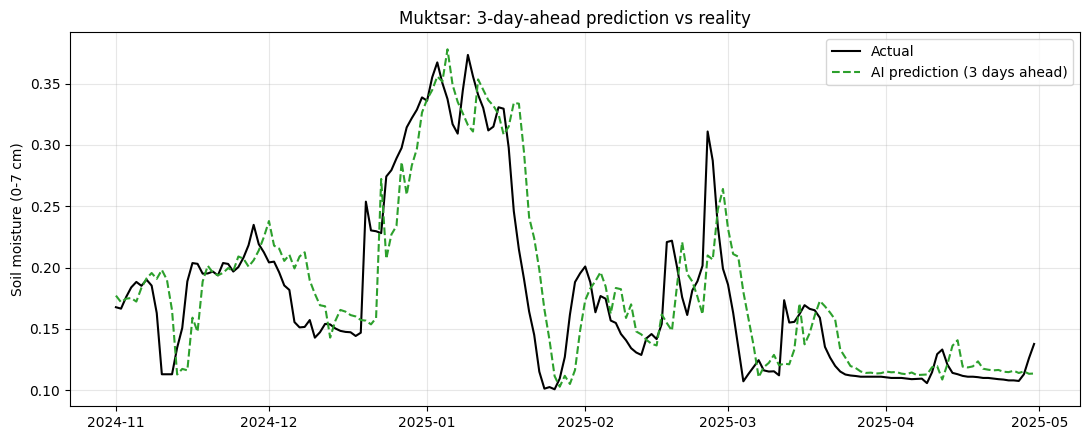

In [10]:
# Actual soil moisture 3 days later vs what the model predicted for it
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(s["date"], s["target_sm_h3"], color="black", label="Actual")
ax.plot(s["date"], s["pred_h"], color="tab:green", ls="--", label="AI prediction (3 days ahead)")

ax.set_ylabel("Soil moisture (0-7 cm)")
ax.set_title(f"{DISTRICT}: 3-day-ahead prediction vs reality")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT}/plot3_pred_vs_actual.png", dpi=200)
plt.show()

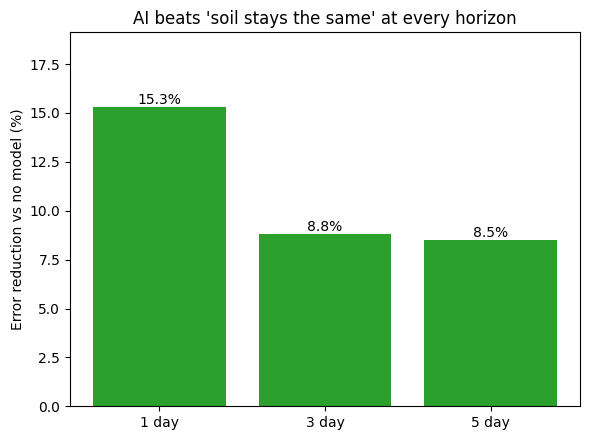

In [11]:
# Percent lower error than "tomorrow = today" at each forecast horizon
fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar([f"{h} day" for h in res["horizon_days"]], res["improvement_%"], color="tab:green")

# Write the exact percentage on top of each bar
ax.bar_label(bars, fmt="%.1f%%")
ax.set_ylabel("Error reduction vs no model (%)")
ax.set_title("AI beats 'soil stays the same' at every horizon")
ax.set_ylim(0, res["improvement_%"].max() * 1.25)
plt.tight_layout()
plt.savefig(f"{OUT}/plot4_horizons.png", dpi=200)
plt.show()

In [12]:
import json
import os

# Exact feature order the model expects
json.dump(FEATURES, open(f"{OUT}/features.json", "w"), indent=2)

# Per-district dry threshold (25th percentile of wheat soil moisture) plus the chosen safety margin
thr = wheat_train.groupby("district")["sm_0_7"].quantile(0.25).astype(float).to_dict()
json.dump({"margin": float(chosen["model"]), "dry_threshold": thr}, open(f"{OUT}/thresholds.json", "w"), indent=2)

# App lookup table: all engineered features for 2023+ so the app needs no feature code
cols = ["date", "district", "crop", "days_after_sowing", "sm_0_7"] + FEATURES
app_df = df[df["date"].dt.year >= 2023][list(dict.fromkeys(cols))]
app_df.to_csv(f"{OUT}/app_data.csv", index=False)
print(os.path.getsize(f"{OUT}/app_data.csv") / 1e6, "MB")

19.195381 MB
